# Solving the curlcurl eigenvalue problem using explicit methods

### by M. Wess, 2025
*This Notebook is part of the `dualcellspaces` [documentation](https://ngsolve.github.io/dcm) for the addon package implementing the Dual Cell method in [NGSolve](https://ngsolve.org), as well as part of the `td_evp` [documentation](https://markuswess.github.io/td_evp/) on the implementation of time-domain methods for resonance problems.* 

We show how to numerically solve the Maxwell eigenvalue problem combining `dualcellspaces` package with the ideas from

[1] L. Nannen and M. Wess, *A Krylov Eigenvalue Solver Based on Filtered Time Domain Solutions*, arXiv prepreint, 2024, [https://doi.org/10.48550/arXiv.2402.08515](https://doi.org/10.48550/arXiv.2402.08515).

Moreover we compare the time domain method to LOBPCG.

## Problem setting

We want to approximate the eigenvectors and eigenfunctions of the problem to find $\tilde\omega\in\mathbb R, E\in H(\mathrm{curl})(\Omega)$ for some domain $\Omega\subset\mathbb R^3$ such that

$$
\mathrm{curl}\mathrm{curl}E(x) = \tilde\omega^2 E(x)
$$
with natural boundary conditions.



## Setting up the discrete Problem

We start by doing the necessary imports

In [9]:
from ngsolve import *
import dualcellspaces as dcs
from ngsolve.webgui import Draw
import numpy as np
from netgen.occ import *
import matplotlib.pyplot as pl
import scipy.linalg as spl
from ngsolve.solvers import LOBPCG

In [10]:
maxh = 1
order = 2
lx = ly = lz = np.pi

In [11]:
geo = OCCGeometry(Box((0,0,0),(lx,ly,lz)))
mesh = Mesh(geo.GenerateMesh(maxh=maxh))
Draw(mesh)

WebGLScene

In [12]:
fes_E = dcs.HCurlDualCells3D(mesh, order=order)
fes_H = dcs.HCurlPrimalCells3D(mesh,order=order)

fes = fes_E*fes_H
print("total DoFs:",fes.ndof)
print("DoFs E:",fes_E.ndof)
gf = GridFunction(fes)
gfE, gfH = gf.components


#integral symbols with special integration rules
dxE = dx(intrules=fes_E.GetIntegrationRules())
dxH = dx(intrules=fes_H.GetIntegrationRules())

dxw = dx(intrules=dcs.GetIntegrationRules(2*order+4))
dSw = dx(element_boundary=True,intrules=dcs.GetIntegrationRules(2*order+4))


#mixed bilinear form
E,dE = fes_E.TnT()
H,dH = fes_H.TnT()

normal = specialcf.normal(3)
Curl = BilinearForm(E*curl(dH)*dxw+E*Cross(dH,normal)*dSw, geom_free=True).Assemble().mat

SetHeapSize(int(2e9))
#prepare mass operators

with TaskManager():
    massH_inv = fes_H.Mass(1).Inverse()
    massE = fes_E.Mass(1)
    massE_inv = fes_E.Mass(1).Inverse(freedofs=fes_E.FreeDofs())

total DoFs: 101256
DoFs E: 51552


## Solving the problem with LOBPCG

To use LOBPCG we need to deal with the kernel of the $\mathrm{curl}$-operator. The `dualcellspaces` package provides the fitting $H^1$-space and $\nabla$-operator respecting the discrete exact sequence properties. 

In [13]:
fespot = fes_E.GetPotentialSpace()
phi, dphi = fespot.TnT()
Grad = BilinearForm(grad(phi)*dE*dxE).Assemble()
gmat = Grad.mat.DeleteZeroElements(1e-12)

massPot = BilinearForm(phi*dphi*dxw, diagonal=True).Assemble()
with TaskManager():
    massPot_inv = massPot.mat.Inverse()

ccdd = Curl.T @ massH_inv @ Curl + 5000*gmat@massPot_inv@gmat.CreateTranspose()

Now we solve the stabilized problem using LOBPCG. As a preconditioner we just use the inverse of the $E$-mass matrix, which leads to very slow convergence. Thus we cheat a little by setting the initial vectors to projections of analytical eigenfunctions.

In [19]:
nevs = 5
initvecs = GridFunction(fes_E,multidim=nevs)

for i in range(nevs):
    initvecs.vecs[i].SetRandom()


initvecs.vecs[0].data = massE_inv*LinearForm(dE*CF((sin(x)*cos(y),-cos(x)*sin(y),0))*dxE).Assemble().vec
initvecs.vecs[1].data = massE_inv*LinearForm(dE*CF((0,sin(y)*cos(z),-cos(y)*sin(z)))*dxE).Assemble().vec
initvecs.vecs[2].data = massE_inv*LinearForm(dE*CF((sin(x)*cos(z),0,-cos(x)*sin(z)))*dxE).Assemble().vec
initvecs.vecs[3].data = massE_inv*LinearForm(dE*CF((2*sin(x)*cos(y)*cos(z),-cos(x)*sin(y)*cos(z),-cos(x)*cos(y)*sin(z)))*dxE).Assemble().vec

ccdd = Curl.T @ massH_inv @ Curl + 5000*gmat@massPot_inv@gmat.CreateTranspose()   

with TaskManager():
    lams,vecs = LOBPCG(ccdd, massE, pre=massE_inv, maxit=100, initial = initvecs.vecs,
                       printrates = True)
print("approximated evs: ",lams)

0 : [33.4046934272116, 36.016233488457196, 38.934276532741016, 66.62630888011739, 1120107.5100885816]
1 : [15.129668363772145, 15.91062363889624, 17.773121821658947, 29.141884505280924, 714288.618884463]
2 : [8.318941291968114, 8.889993152757068, 10.28936609942856, 15.898130640533306, 554305.1737834862]
3 : [5.375921047123504, 5.604648829583592, 6.425176869746773, 9.970062049516736, 460884.1107982093]
4 : [3.8519466102527344, 4.027587570510584, 4.461493387167848, 6.935792184815598, 395344.2231369249]
5 : [3.056800820153552, 3.2266388728540236, 3.438113717094799, 5.269733923989201, 345038.5953065827]
6 : [2.641177127595946, 2.762298271633232, 2.8645422066960378, 4.404423101909524, 301633.1707222996]
7 : [2.3989129224111814, 2.4875835072079937, 2.5448688525065117, 3.8861253064302916, 261203.47106939484]
8 : [2.2598162102439, 2.325987520962622, 2.3598986182173753, 3.5920854456131037, 222239.1205222841]
9 : [2.1766983391253927, 2.219592734737207, 2.2452715956686258, 3.402899773163022, 1862

## The filtered problem

The idea from [[1]](https://doi.org/10.48550/arXiv.2402.08515) in short is to use the solution of the time-domain Maxwell problem 

$$
\begin{aligned}
\partial_t^2 e(t,x) + \mathrm{curl}\mathrm{curl}e(t,x)&=0\\
e(0,x)&=E_0(x)
\end{aligned}
$$
To define the filtered operator $\tilde \Pi_\alpha$ by
$$
(\tilde \Pi_{\alpha} E^0)(x) = \int_0^\infty e(t,x)\alpha(t)dt
$$
for some weight function $\alpha$ with final support in $\mathbb R$.

It can be shown that for an eigenpair $(\tilde\omega, E)$ of the Maxwell eigenvalue problem $(\beta(\tilde\omega),E)$ is an eigenpair of $\Pi_\alpha$ for 

$$
\tilde \beta(s):=\int_0^\infty \cos(ts)\alpha(t)dt.
$$

## Discretizations

The same arguments hold true if we replace the continuous problem by the discrete eigenvalue problem

$$
\mathbf S \mathbf E = \omega^2\mathbf M \mathbf E
$$
where $\mathbf S,\mathbf M$ are the discretization of the $\mathrm {curl}\mathrm {curl}$ and the mass matrix and $\mathbf E$ is the coefficient vector of the discrete eigenfunctions.

Discretizing the semi-discrete time domain problem by a time-stepping and the integral by a trapezoidal rule leads to the discrete filter

$$
(\Pi_\alpha)(\mathbf{e^0})=\tau \sum_{j=0}^M \alpha(\tau j) \mathbf e^j
$$
where $\mathbf e^j$ is the time-domain solution at time step number $j$.

Then if $\omega,\mathbf E$  is an eigenpair of the discrete problem $(\beta(\omega),\mathbf E)$ is an eigenpair of the operator $\Pi_\alpha$ with
$$
\beta(s):= \tau \sum_{j=0}^M \lambda_j(s)\alpha(\tau j)
$$
and $\lambda_j$ is the approximation of the scalar problem
$$
\partial_t^2 l(t)+s^2 l(t)=0,\quad l(0) = 1
$$
by the chosen time-stepping.

### Choosing the filter and solving the problem

The idea is now to choose the weight function $\alpha$ such that the resulting filter $\beta$ is maximal in a region where the sought after eigenvalues are and close to zero otherwise. Then applying e.g., an Arnoldi algorithm to the filtered operator $\Pi_\alpha$ will yield approximations to the eigenfunctions where $\beta$ is maximal, which we know to be eigenvectors of the original problems corresponding to eigenvalues in the interesting region. Lastly we solve the original problem projected onto the space spanned by the Krylov space of $\Pi_\alpha$.

We define the filtered operator as a class. Since we use a mixed method for the spacial discretization we need to supply the (inverse) mass matrices for the two fieds, as well as the discrete curl operator and the parameters for the time-discretization and filtering.

In [24]:
class FilteredC(BaseMatrix):
    def __init__(self, mata, matm_inv, tau, weights, freedofs = None):
        super().__init__()
        self.dt = tau
        self.weights = weights
        self.nsteps = len(weights)

        self.mata = mata
        self.matm_inv = matm_inv

        self.freedofs=freedofs


        self.vecu = self.mata.CreateColVector()
        self.tmpvec1 = self.mata.CreateColVector()
        self.tmpvec2 = self.mata.CreateColVector()


    def CreateColVector(self):
        return self.mata.CreateColVector()

    def Shape(self):
        return self.mata.shape

    def CreateVector(self,col):
        return self.mata.CreateVector(col)

    def Mult(self,rhs,out):
        with TaskManager():
            self.vecu.data = rhs
            tau = self.dt
            out.data = tau*self.weights[0]*self.vecu
            t = 0

            unew = self.tmpvec1
            uold = self.tmpvec2
            uold.data = self.vecu

            for i in range(1,self.nsteps):
                t += tau
                #print("\r time = {}, step = {}".format(t,i),end="")

                unew.data = 2*self.vecu - uold
                unew.data -= tau**2 * self.matm_inv@self.mata * self.vecu
                if self.freedofs:
                    unew.data[~self.freedofs] = 0.
                uold.data = self.vecu
                self.vecu.data = unew.data

                out.data += tau*self.weights[i]*self.vecu


To obtain a stable method we need to respect the CFL condition of the time-domain problem. Thus we apply a simple power iteration to determine the largest magnitude eigenvalue of the discrete problem:

In [25]:
massinv = massE_inv
mass = massE
stiffness = Curl.T@massH_inv@Curl
tol = 1e-4
tmpv = stiffness.CreateVector()
tmpv2 = stiffness.CreateVector()
tmpv.SetRandom()
tmpv /= tmpv.Norm()
mus = [1]
for i in range(500):
    #print("i = {}".format(i))
    tmpv2.data = tmpv
    tmpv.data = massinv@stiffness*tmpv2
    mu = InnerProduct(tmpv2,tmpv)/InnerProduct(tmpv2,tmpv2)
    tmpv /= tmpv.Norm()
    mus.append(mu)
    if mus[-1]/mus[-2]<1+tol:
        break

lammax = mus[-1]*(1+tol*200) #some safety factors
print("estimated largest eigenvalue: ",lammax)
tau = np.sqrt(4/lammax)
print("by power iteration stable for tau = {}".format(tau))

estimated largest eigenvalue:  8332.166952253809
by power iteration stable for tau = 0.02191043570892399


Next we need to pick suitable parameters for the time-domain filtering. We look for eigenvalues $\lambda\in[1,3]$ and plot the resulting discrete filter.

(0.0, 10.0)

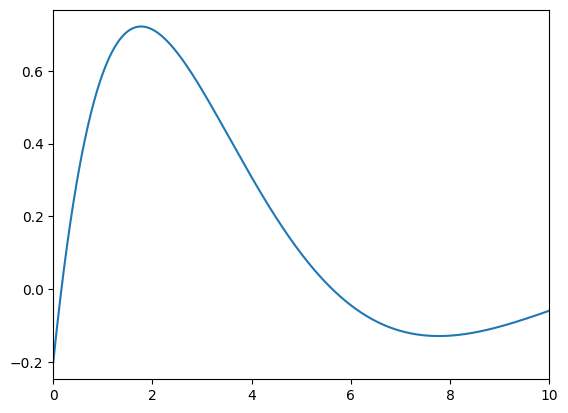

In [30]:
# parameters for the filter function
lam_min = 1
lam_max = 3
endT = 3
L = int(endT/tau)


w_min = np.sqrt(lam_min)
w_max = np.sqrt(lam_max)

weightf = lambda t: 4/np.pi*np.cos((w_max+w_min)/2*t)*(w_max-w_min)/2*np.sinc((w_max-w_min)/2*t/np.pi)

weights = weightf(tau*np.arange(L))


def beta(lam):
    if np.isscalar(lam):
        q = 1
    else:
        q = np.ones(lam.shape)

    q_old = q
    out = tau*weights[0]*q
    for alpha in weights[1:]:
        q_new = 2*q-tau**2*lam*q-q_old
        q_old = q
        q = q_new
        out += tau*alpha*q
    return out

betas = beta(np.arange(0,20,0.01))
pl.figure()
pl.plot(omegas,betas);
pl.xlim((0,10))

In [37]:
maxsteps = 20

C = FilteredC(stiffness,massinv,tau,weights)

solveevery = 1

tmpvec = massinv.CreateVector()
tmpvec.SetRandom()
tmpvec.data = 1/tmpvec.Norm()*tmpvec
tmpvec2 = massinv.CreateVector()

vecs = MultiVector(tmpvec,0)
vecs.Append(tmpvec)
for i in range(maxsteps):
    print("\n Krylowstep = {}".format(i))

    tmpvec.data = C*vecs[-1]
    vecs.AppendOrthogonalize(tmpvec)

    if i%solveevery == 0:
        tvecs = MultiVector(tmpvec,len(vecs))
        tvecs.data = stiffness*vecs
        tvecs2 = MultiVector(tmpvec,len(vecs))
        tvecs2.data = mass*vecs

        matm_proj = InnerProduct(tvecs2,vecs)
        mats_proj = InnerProduct(tvecs,vecs)
        lam,v = spl.eigh(mats_proj.NumPy(),matm_proj.NumPy())

        #compute residuals
        eigf =(vecs*Matrix(v.real)).Evaluate()
        res = []
        tmpvec2[:] = 0
        for i in range(len(lam)):
            tmpvec2.data = massinv@stiffness*eigf[i]
            tmpvec2.data -= lam[i]*eigf[i]
            res.append(tmpvec2.Norm()/eigf[i].Norm())

print("approximated eigenvalues: ", lam)
print("residuals: ",res)


 Krylowstep = 0

 Krylowstep = 1

 Krylowstep = 2

 Krylowstep = 3

 Krylowstep = 4

 Krylowstep = 5

 Krylowstep = 6

 Krylowstep = 7

 Krylowstep = 8

 Krylowstep = 9

 Krylowstep = 10

 Krylowstep = 11

 Krylowstep = 12

 Krylowstep = 13

 Krylowstep = 14

 Krylowstep = 15

 Krylowstep = 16

 Krylowstep = 17

 Krylowstep = 18

 Krylowstep = 19
approximated eigenvalues:  [-2.31937008e-14  2.00012552e+00  2.00018279e+00  2.00020235e+00
  3.00032534e+00  3.00039426e+00  5.00149581e+00  6.09205541e+00
  8.00403142e+00  9.00678423e+00  1.06354292e+01  1.39605119e+01
  1.42052547e+01  1.96488328e+01  2.55175163e+01  3.69844306e+01
  7.02764349e+01  1.28545191e+02  3.13037437e+02  6.76016298e+02
  9.80999056e+02]
residuals:  [2.1989909295670403e-09, 0.00019775980295800953, 0.0013192117691427378, 0.0005301841411562754, 3.5258010954220083e-08, 3.6911969388271684e-08, 0.007333758719569671, 15.43501053185778, 0.001703512655918669, 0.01461423689933618, 13.416289340398531, 9.509263003677018, 21